In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
%matplotlib inline

In [2]:
np.random.seed(2024)
import tensorflow as tf
tf.random.set_seed(2024)

In [3]:
from tensorflow.keras.datasets import fashion_mnist

In [4]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

In [5]:
fashion_classes = {
    0: 'Футболка',
    1: 'Брюки',
    2: 'Свитер',
    3: 'Платье',
    4: 'Пальто',
    5: 'Туфли',
    6: 'Рубашка',
    7: 'Кроссовки',
    8: 'Сумка',
    9: 'Ботинки'
}


In [6]:
print(f"Размер обучающей выборки: {train_images.shape}")
print(f"Размер тестовой выборки: {test_images.shape}")


Размер обучающей выборки: (60000, 28, 28)
Размер тестовой выборки: (10000, 28, 28)


In [7]:
train_images = train_images / 255.0
test_images = test_images / 255.0

In [8]:
train_labels_cat = utils.to_categorical(train_labels, 10)
test_labels_cat = utils.to_categorical(test_labels, 10)

In [9]:
EXPERIMENT_1_ENABLED = True
EXPERIMENT_2_ENABLED = True  
EXPERIMENT_3_ENABLED = True   

In [10]:
if EXPERIMENT_1_ENABLED:

    
    train_flat = train_images.reshape(-1, 784)
    test_flat = test_images.reshape(-1, 784)
    
    mlp_model = Sequential([
        Input(shape=(784,)),
        Dense(300, activation='relu', name='hidden_layer_1'),
        Dropout(0.4, name='dropout_1'),
        Dense(150, activation='relu', name='hidden_layer_2'),
        Dropout(0.3, name='dropout_2'),
        Dense(10, activation='softmax', name='output_layer')
    ], name='Dense_Neural_Network')
    
    mlp_model.compile(
        optimizer=Adam(learning_rate=0.0008),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    mlp_model.summary()
    
    start_time = time.time()
    history_mlp = mlp_model.fit(
        train_flat, train_labels_cat,
        batch_size=200,
        epochs=25,
        validation_split=0.2,
        verbose=1,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
            ModelCheckpoint('mlp_best.keras', save_best_only=True, monitor='val_accuracy')
        ]
    )
    elapsed_time_mlp = time.time() - start_time
    
    test_metrics_mlp = mlp_model.evaluate(test_flat, test_labels_cat, verbose=0)
    print(f"\nТестовая точность: {test_metrics_mlp[1]:.4f}")
    print(f"Время обучения: {elapsed_time_mlp/60:.2f} минут")
else:
    print("\nЭксперимент 1 пропущен")
    test_metrics_mlp = [0, 0]
    history_mlp = None
    elapsed_time_mlp = 0

Model: "Dense_Neural_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)               │ (None, 300)                 │         235,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 300)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 150)                 │          45,150 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 150)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 282,160 (1.08 MB)

 Trainable params: 282,160 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7451 - loss: 0.7256 - val_accuracy: 0.8436 - val_loss: 0.4414
Epoch 2/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8304 - loss: 0.4732 - val_accuracy: 0.8568 - val_loss: 0.3966
Epoch 3/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8486 - loss: 0.4239 - val_accuracy: 0.8643 - val_loss: 0.3751
Epoch 4/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8570 - loss: 0.3962 - val_accuracy: 0.8654 - val_loss: 0.3596
Epoch 5/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8632 - loss: 0.3794 - val_accuracy: 0.8741 - val_loss: 0.3469
Epoch 6/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8694 - loss: 0.3608 - val_accuracy: 0.8755 - val_loss: 0.3399
Epoch 7/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8721 - loss: 0.3507 - val_accuracy: 0.8794 - val_loss: 0.3292
Epoch 8/25
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8759 - loss: 0.3361 - val_accuracy: 0.

In [11]:
if EXPERIMENT_2_ENABLED:

    train_cnn = train_images.reshape(-1, 28, 28, 1)
    test_cnn = test_images.reshape(-1, 28, 28, 1)
    
    cnn_model = Sequential([
        Input(shape=(28, 28, 1), name='input_layer'),
        
        Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1_1'),
        MaxPooling2D((2, 2), name='pool1'),
        Dropout(0.25, name='dropout_conv1'),
        
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2_1'),
        MaxPooling2D((2, 2), name='pool2'),
        Dropout(0.25, name='dropout_conv2'),
        
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3_1'),
        MaxPooling2D((2, 2), name='pool3'),
        Dropout(0.3, name='dropout_conv3'),
        
        Flatten(name='flatten'),
        Dense(256, activation='relu', name='dense_1'),
        Dropout(0.5, name='dropout_dense'),
        Dense(10, activation='softmax', name='output')
    ], name='Convolutional_Neural_Network')
    
    cnn_model.compile(
        optimizer=RMSprop(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    cnn_model.summary()
    
    start_time = time.time()
    history_cnn = cnn_model.fit(
        train_cnn, train_labels_cat,
        batch_size=128,
        epochs=30,
        validation_split=0.15,
        verbose=1,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            ModelCheckpoint('cnn_best.keras', save_best_only=True, monitor='val_accuracy')
        ]
    )
    elapsed_time_cnn = time.time() - start_time
    
    test_metrics_cnn = cnn_model.evaluate(test_cnn, test_labels_cat, verbose=0)
    print(f"\nТестовая точность: {test_metrics_cnn[1]:.4f}")
    print(f"Время обучения: {elapsed_time_cnn/60:.2f} минут")
else:
    print("\nЭксперимент 2 пропущен")
    test_metrics_cnn = [0, 0]
    history_cnn = None
    elapsed_time_cnn = 0

Model: "Convolutional_Neural_Network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                     │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_conv1 (Dropout)              │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2_1 (Conv2D)                     │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_conv2 (Dropout)              │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3_1 (Conv2D)                     │ (None, 7, 7, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool3 (MaxPooling2D)                 │ (None, 3, 3, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_conv3 (Dropout)              │ (None, 3, 3, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1152)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_dense (Dropout)              │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 390,410 (1.49 MB)

 Trainable params: 390,410 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.7251 - loss: 0.7305 - val_accuracy: 0.8416 - val_loss: 0.4316
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.8421 - loss: 0.4330 - val_accuracy: 0.8646 - val_loss: 0.3648
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8655 - loss: 0.3711 - val_accuracy: 0.8872 - val_loss: 0.3173
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.8765 - loss: 0.3372 - val_accuracy: 0.8883 - val_loss: 0.3007
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.8857 - loss: 0.3158 - val_accuracy: 0.9002 - val_loss: 0.2724
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8920 - loss: 0.2965 - val_accuracy: 0.9037 - val_loss: 0.2614
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.8961 - loss: 0.2856 - val_accuracy: 0.9089 - val_loss: 0.2448
Epoch 8/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.8996 - loss: 0.2747 - 

In [12]:
if EXPERIMENT_3_ENABLED:
    
    if not EXPERIMENT_2_ENABLED:
        train_cnn = train_images.reshape(-1, 28, 28, 1)
        test_cnn = test_images.reshape(-1, 28, 28, 1)
    
    optimized_cnn = Sequential([
        Input(shape=(28, 28, 1), name='input'),
        
        Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv1'),
        BatchNormalization(name='block1_bn1'),
        Conv2D(32, (3, 3), activation='relu', padding='same', name='block1_conv2'),
        MaxPooling2D((2, 2), name='block1_pool'),
        Dropout(0.25, name='block1_dropout'),
        
        Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv1'),
        BatchNormalization(name='block2_bn1'),
        Conv2D(64, (3, 3), activation='relu', padding='same', name='block2_conv2'),
        MaxPooling2D((2, 2), name='block2_pool'),
        Dropout(0.3, name='block2_dropout'),
        
        Flatten(name='flatten_layer'),
        Dense(128, activation='relu', name='dense_layer1'),
        BatchNormalization(name='dense_bn1'),
        Dropout(0.4, name='dense_dropout1'),
        Dense(10, activation='softmax', name='output_layer')
    ], name='CPU_Optimized_CNN')
    

    optimized_cnn.compile(
        optimizer=Adam(learning_rate=0.001), 
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    
    optimized_cnn.summary()
    

    start_time = time.time()
    history_optimized = optimized_cnn.fit(
        train_cnn, train_labels_cat,
        batch_size=128,  
        epochs=25,      
        validation_split=0.15,
        verbose=1,
        callbacks=[
            EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
            ReduceLROnPlateau(factor=0.5, patience=2, verbose=1, monitor='val_loss')
        ]
    )
    elapsed_time_optimized = time.time() - start_time
    

    test_metrics_optimized = optimized_cnn.evaluate(test_cnn, test_labels_cat, verbose=0)
    print(f"\nТЕСТОВАЯ ТОЧНОСТЬ: {test_metrics_optimized[1]:.4f}")
    print(f"Время обучения: {elapsed_time_optimized/60:.2f} минут")
else:
    print("\nЭксперимент 3 пропущен")
    test_metrics_optimized = [0, 0]
    history_optimized = None
    elapsed_time_optimized = 0

Model: "CPU_Optimized_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)                │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_bn1 (BatchNormalization)      │ (None, 28, 28, 32)          │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 28, 28, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_dropout (Dropout)             │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_bn1 (BatchNormalization)      │ (None, 14, 14, 64)          │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_dropout (Dropout)             │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_layer (Flatten)              │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_layer1 (Dense)                 │ (None, 128)                 │         401,536 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_bn1 (BatchNormalization)       │ (None, 128)                 │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_dropout1 (Dropout)             │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 468,714 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 37s 88ms/step - accuracy: 0.8151 - loss: 0.5276 - val_accuracy: 0.6176 - val_loss: 0.9892 - learning_rate: 0.0010
Epoch 2/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - accuracy: 0.8837 - loss: 0.3298 - val_accuracy: 0.9008 - val_loss: 0.2697 - learning_rate: 0.0010
Epoch 3/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 35s 88ms/step - accuracy: 0.8988 - loss: 0.2849 - val_accuracy: 0.8938 - val_loss: 0.2792 - learning_rate: 0.0010
Epoch 4/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.9082 - loss: 0.2567 - val_accuracy: 0.9180 - val_loss: 0.2349 - learning_rate: 0.0010
Epoch 5/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - accuracy: 0.9154 - loss: 0.2350 - val_accuracy: 0.9184 - val_loss: 0.2322 - learning_rate: 0.0010
Epoch 6/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step - accuracy: 0.9194 - loss: 0.2235 - val_accuracy: 0.9221 - val_loss: 0.2171 - learning_rate: 0.0010
Epoch 7/25
399/399 ━━━━━━━━━━━━━━━━━━━━ 36s 91ms/step - accuracy: 0.9259 - l

In [13]:
experiment_results = []
if EXPERIMENT_1_ENABLED:
    experiment_results.append(('Полносвязная сеть', test_metrics_mlp[1], elapsed_time_mlp/60))
if EXPERIMENT_2_ENABLED:
    experiment_results.append(('Базовая CNN', test_metrics_cnn[1], elapsed_time_cnn/60))
if EXPERIMENT_3_ENABLED:
    experiment_results.append(('Оптимизированная CNN', test_metrics_optimized[1], elapsed_time_optimized/60))

if experiment_results:
    results_df = pd.DataFrame(experiment_results, columns=['Архитектура', 'Точность', 'Время (мин)'])
    results_df = results_df.sort_values('Точность', ascending=False)
    print(results_df.to_string(index=False))
    
    max_accuracy = max(accuracy for _, accuracy, _ in experiment_results)
    if max_accuracy >= 0.90:
        print(f"\nРЕЗУЛЬТАТ: ЗАДАЧА ВЫПОЛНЕНА! Достигнута точность {max_accuracy:.4f}, что превышает требуемый порог 0.90")
    else:
        print(f"\nРЕЗУЛЬТАТ: Необходимо продолжить оптимизацию. Лучшая точность {max_accuracy:.4f} не достигает требуемого порога 0.90")
else:
    print("Не выполнено ни одного эксперимента для анализа")


         Архитектура  Точность  Время (мин)
Оптимизированная CNN    0.9369    14.544409
         Базовая CNN    0.9190     4.851077
   Полносвязная сеть    0.8856     0.419672

РЕЗУЛЬТАТ: ЗАДАЧА ВЫПОЛНЕНА! Достигнута точность 0.9369, что превышает требуемый порог 0.90


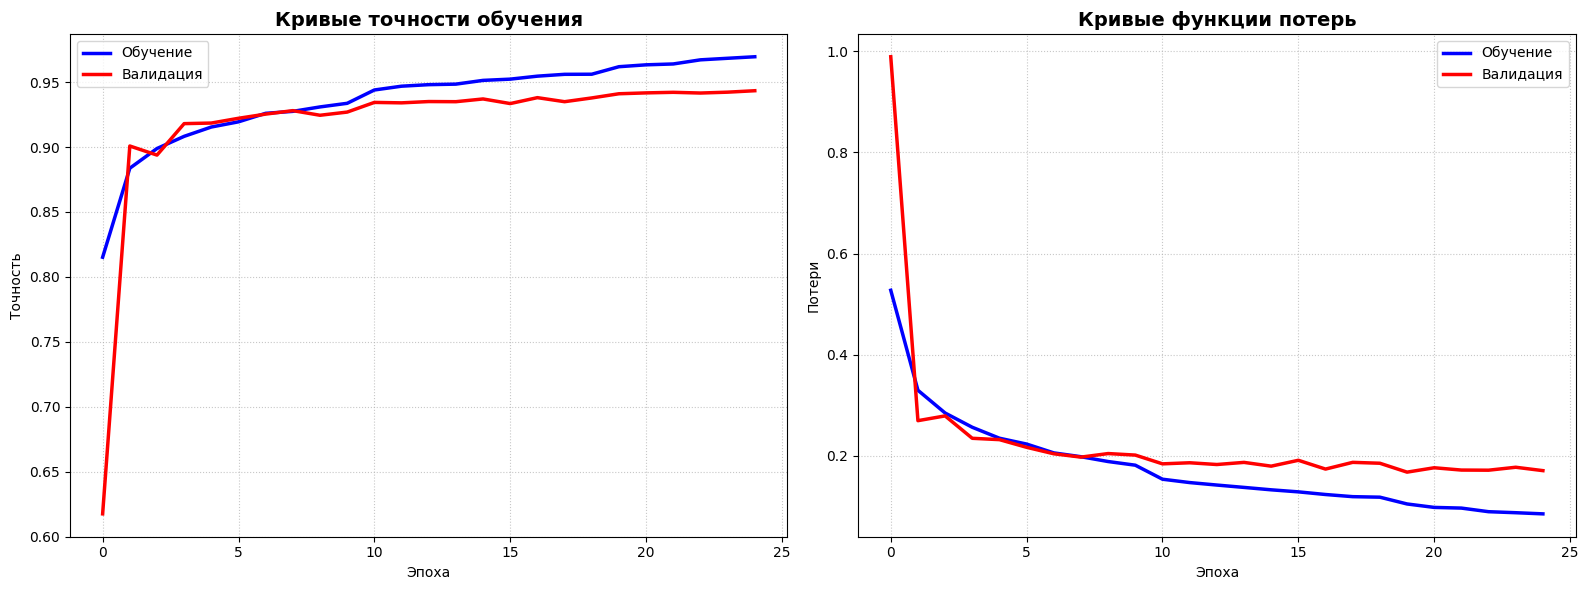

In [14]:
if experiment_results:

    training_histories = []
    if EXPERIMENT_1_ENABLED and history_mlp:
        training_histories.append(history_mlp)
    if EXPERIMENT_2_ENABLED and history_cnn:
        training_histories.append(history_cnn)
    if EXPERIMENT_3_ENABLED and history_optimized:
        training_histories.append(history_optimized)
    
    if training_histories:
        accuracies = [
            test_metrics_mlp[1] if EXPERIMENT_1_ENABLED else 0,
            test_metrics_cnn[1] if EXPERIMENT_2_ENABLED else 0,
            test_metrics_optimized[1] if EXPERIMENT_3_ENABLED else 0
        ]
        
        best_index = np.argmax(accuracies)
        best_history = training_histories[min(best_index, len(training_histories)-1)]
        
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        
        axes[0].plot(best_history.history['accuracy'], 'b', linewidth=2.5, label='Обучение')
        axes[0].plot(best_history.history['val_accuracy'], 'r', linewidth=2.5, label='Валидация')
        axes[0].set_title('Кривые точности обучения', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Эпоха')
        axes[0].set_ylabel('Точность')
        axes[0].legend(loc='best')
        axes[0].grid(True, linestyle=':', alpha=0.7)
        
        axes[1].plot(best_history.history['loss'], 'b', linewidth=2.5, label='Обучение')
        axes[1].plot(best_history.history['val_loss'], 'r', linewidth=2.5, label='Валидация')
        axes[1].set_title('Кривые функции потерь', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Эпоха')
        axes[1].set_ylabel('Потери')
        axes[1].legend(loc='best')
        axes[1].grid(True, linestyle=':', alpha=0.7)
        
        plt.tight_layout()
        plt.show()
